# Function 4 - Week 4: observation review

Review what the completed experiments have shown before using a model to choose
the next query. This notebook examines measured inputs and outputs; fitted
relationships, predictive uncertainty and candidate selection belong in
[model review and next query](model_predictions.ipynb).

The independent Week 4 `observations.csv` contains **30 initial observations
and three returned queries**, including the Week 3 return received on
**14 October 2026**. Larger signed outputs are better. The four input settings
each lie in `[0, 1)`. Earlier weekly notebooks remain the record of the evidence
and reasoning available at those times.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import display

week_dir = Path.cwd().resolve()
shared_dir = week_dir.parents[1] / "Shared"
if not (week_dir / "observation_review.ipynb").is_file():
    raise FileNotFoundError("Run this notebook from its own Function_4/Week_04 folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from output_helpers import summarise_output_observations
from query_budget import remaining_queries, TOTAL_QUERY_WEEKS
from observation_review_helpers import (
    plot_input_profiles,
    plot_output_review,
    plot_round_progress,
)

figures = week_dir / "figures"
figures.mkdir(parents=True, exist_ok=True)

## 1. Establish this week's evidence

Keep the supplied observations together as one initial batch. Their row order
does not describe a sequence of optimisation decisions. The three later rounds
each contain one deliberately selected query.

In [2]:
data = pd.read_csv(week_dir / "observations.csv", float_precision="round_trip")
input_columns = ["x1", "x2", "x3", "x4"]
expected_columns = ["observation_id", "source_round", *input_columns, "y"]
if list(data.columns) != expected_columns:
    raise ValueError("Unexpected observation columns for Function 4.")
if data.isna().any().any() or not data["observation_id"].is_unique:
    raise ValueError("Observations need complete values and distinct IDs.")
if not np.isfinite(data[["source_round", *input_columns, "y"]].to_numpy()).all():
    raise ValueError("Inputs, outputs and rounds must be finite.")
if not ((data[input_columns] >= 0) & (data[input_columns] < 1)).all().all():
    raise ValueError("Input settings must lie in [0, 1).")
if data["source_round"].value_counts().to_dict() != {0: 30, 1: 1, 2: 1, 3: 1}:
    raise ValueError("This review expects the fixed Week 4 snapshot through round 3.")

initial = data.loc[data["source_round"].eq(0)]
returned = data.loc[data["source_round"].gt(0)].sort_values("source_round")
output_review = summarise_output_observations(data, input_columns=input_columns)
latest = data.loc[output_review["latest_mask"]].iloc[0]
earlier = data.loc[data["source_round"].lt(latest["source_round"])]
incumbent = data.loc[data["y"].idxmax()]

display(pd.DataFrame({
    "Evidence": ["Input dimensions", "Initial observations", "Returned queries",
                 "Total observations", "Queries available, including Week 4"],
    "Count": [len(input_columns), len(initial), len(returned), len(data),
              remaining_queries(week_dir)],
}))
print(f"Weekly queries used: {len(returned)}/{TOTAL_QUERY_WEEKS}")

,Evidence,Count
0,Input dimensions,4
1,Initial observations,30
2,Returned queries,3
3,Total observations,33
4,"Queries available, including Week 4",10


Weekly queries used: 3/13


## 2. Place the latest return among the observed outputs

The latest output is **-0.347965**, ranked **2/33 (1 = highest output)**.
It is a strong measured result. The best observed output, called the incumbent,
remains **-0.129918** from round 2. All three returned queries are now the three
highest observations.

In [3]:
print(output_review["report"])

Latest recorded submission: round 3 (1 new output).
Compared with 32 earlier observations (33 outputs in total).
Earlier output range: [-32.625660216, -0.129918145217].

round-03: y = -0.347965098497 (negative); rank 2/33 (1 = highest output).
Inputs: x1 = 0.459127, x2 = 0.368781, x3 = 0.430162, x4 = 0.390645
Within the earlier output range.


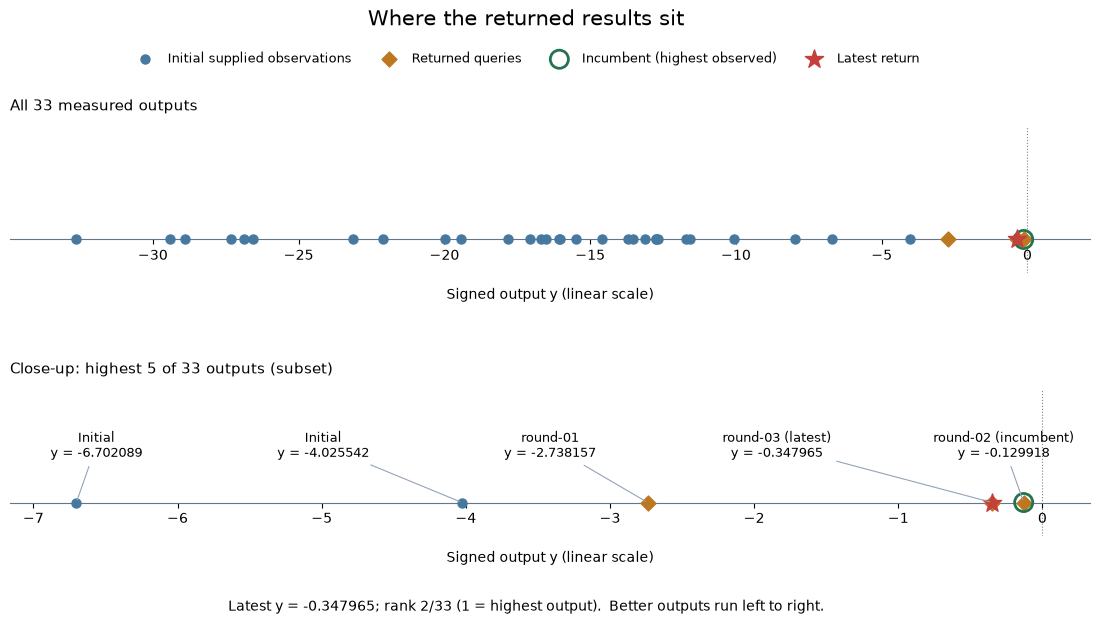

In [4]:
plot_output_review(
    output_review,
    save_to=figures / "observed-output-review.png",
)

Both panels use the original signed output: moving right means a better score.
The full-range panel retains all 33 observations; the labelled close-up separates
the five highest values. No observation is removed from the data or calculations.

These are the outputs at the locations sampled so far. In particular, the later
queries were chosen using earlier evidence, so this view does not estimate the
distribution of scores throughout the input domain. Values near zero are not
evidence of proximity to the maximum: no upper bound of zero has been established.

## 3. Track progress across completed rounds

A high rank describes one result's position. A chronological view answers a
different question: which experiments actually improved the best score seen?
Compare each return with the best available **before that round**, in output
units rather than percentages of a negative score.

In [5]:
running_best = float(initial["y"].max())
progress_rows = [{
    "source_round": 0, "stage": "Initial batch", "returned_y": np.nan,
    "best_y": running_best, "change_vs_prior_best": np.nan,
}]
for _, observation in returned.iterrows():
    value = float(observation["y"])
    change = value - running_best
    running_best = max(running_best, value)
    progress_rows.append({
        "source_round": int(observation["source_round"]),
        "stage": f"Round {int(observation['source_round'])}",
        "returned_y": value, "best_y": running_best,
        "change_vs_prior_best": change,
    })
progress = pd.DataFrame(progress_rows)
display(progress.set_index("stage")[[
    "returned_y", "best_y", "change_vs_prior_best",
]].rename(columns={
    "returned_y": "Returned output", "best_y": "Best observed after stage",
    "change_vs_prior_best": "Return minus previous best",
}).style.format(precision=6, na_rep="—"))

,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,—,-4.025542,—
Round 1,-2.738157,-2.738157,1.287385
Round 2,-0.129918,-0.129918,2.608239
Round 3,-0.347965,-0.129918,-0.218047


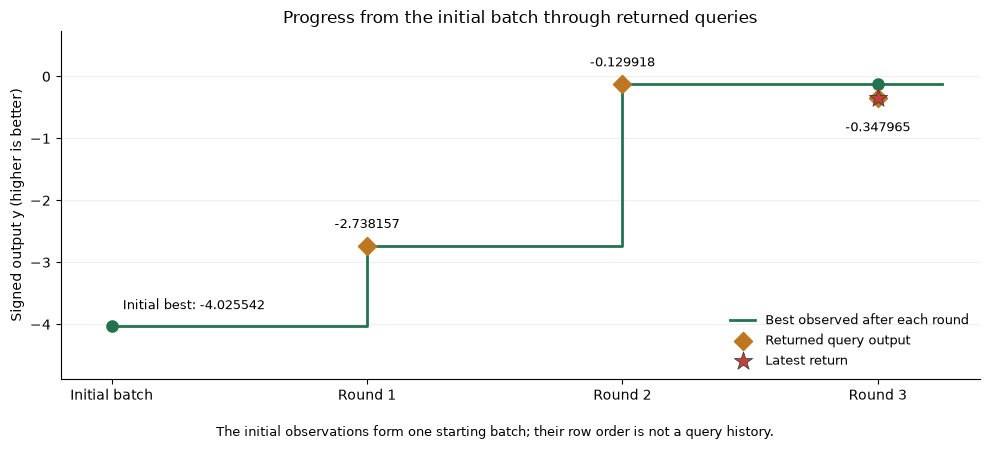

In [6]:
plot_round_progress(progress, save_to=figures / "observed-progress.png")

Rounds 1 and 2 each improved the incumbent; round 3 did not. Nevertheless, all
three returns exceed the initial best of **-4.025542**. The best observed score
has improved by **3.895624 output units** since the initial batch.

This records progress at the chosen locations. Three selected queries do not
establish the superiority of the selection method, and one non-improvement
does not establish a plateau. There is no counterfactual showing what another
sequence of queries would have returned.

## 4. Examine the strongest input combinations

Keep all four coordinates visible together. This table and input-profile figure
show the five strongest measured combinations, with their actual outputs beside
them. Input settings share a fixed 0–1 colour scale; the colours do not represent
performance or fitted input effects.

In [7]:
ranked = data.assign(rank=data["y"].rank(ascending=False, method="min").astype(int))
strongest = ranked.sort_values(["rank", "observation_id"]).head(5)
display(strongest[["rank", "observation_id", "source_round", *input_columns, "y"]]
        .set_index("observation_id")
        .style.format({column: "{:.6f}" for column in [*input_columns, "y"]}))

,rank,source_round,x1,x2,x3,x4,y
observation_id,,,,,,,
round-02,1,2,0.445520,0.390792,0.374106,0.377372,-0.129918
round-03,2,3,0.459127,0.368781,0.430162,0.390645,-0.347965
round-01,3,1,0.377878,0.477308,0.239218,0.435290,-2.738157
initial-028,4,0,0.577766,0.428772,0.425826,0.249007,-4.025542
initial-025,5,0,0.326076,0.472367,0.453192,0.105887,-6.702089


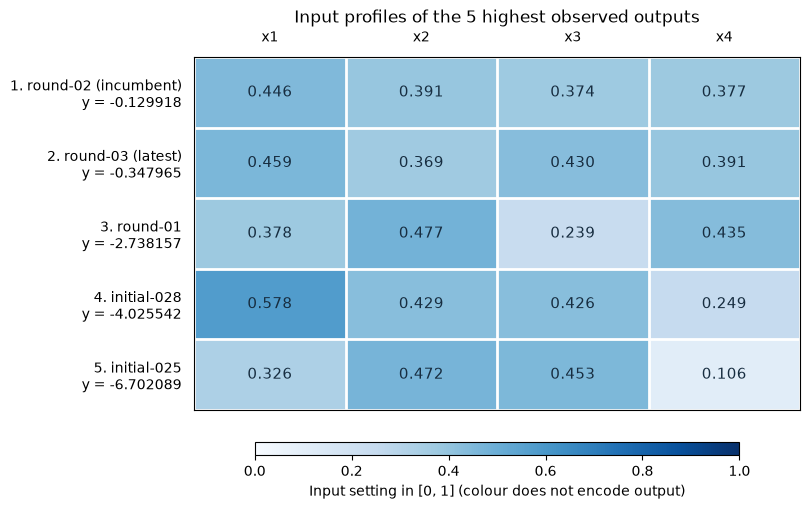

In [8]:
plot_input_profiles(
    strongest,
    input_columns=input_columns,
    latest_id=latest["observation_id"],
    incumbent_id=incumbent["observation_id"],
    save_to=figures / "strongest-input-profiles.png",
)

The [Week 1 review](../Week_01/01-function-4-initial-exploration.ipynb) correctly
noted that its three best observations all had **x4 below 0.25**. That was a
pattern in the initial sample, not an established rule for good results.

All three returned queries now exceed the initial best with **x4 between
0.377372 and 0.435290**. Restricting attention to low x4 would therefore exclude
the strongest combinations measured so far. Other inputs changed too: this
does not show that increasing x4 improves the output, or isolate the effect of
any coordinate. The earlier review remains unchanged; this is the later update
to that interpretation.

### How close is the latest query to the previous best?

Proximity in a two-coordinate projection can conceal differences in the other
inputs. Compare the latest query with the incumbent available before its return,
using every coordinate. Each setting already uses the same 0–1 range, so ordinary
Euclidean distance gives a descriptive geometric comparison without fitting a model.

In [9]:
previous_best = earlier.loc[earlier["y"].idxmax()]
coordinate_change = latest[input_columns].astype(float) - previous_best[input_columns].astype(float)
display(pd.DataFrame({
    "Previous best": previous_best[input_columns].astype(float),
    "Latest query": latest[input_columns].astype(float),
    "Latest minus previous best": coordinate_change,
}).style.format(precision=6))

earlier_distances = np.linalg.norm(
    earlier[input_columns].to_numpy() - latest[input_columns].to_numpy(dtype=float),
    axis=1,
)
nearest_previous = earlier.iloc[earlier_distances.argmin()]
distance_to_previous_best = float(np.linalg.norm(coordinate_change.to_numpy()))
latest_output_change = float(latest["y"] - previous_best["y"])
print(f"Previous best: {previous_best['observation_id']}; y = {previous_best['y']:.6f}")
print(f"Full four-input distance to previous best: {distance_to_previous_best:.6f}")
print(f"Latest output minus previous best: {latest_output_change:+.6f}")
print(f"Nearest earlier observation: {nearest_previous['observation_id']} "
      f"(distance {earlier_distances.min():.6f})")
print(f"Repeated full input combinations: {int(data.duplicated(input_columns).sum())}")

,Previous best,Latest query,Latest minus previous best
x1,0.445520,0.459127,0.013607
x2,0.390792,0.368781,-0.022011
x3,0.374106,0.430162,0.056056
x4,0.377372,0.390645,0.013273


Previous best: round-02; y = -0.129918
Full four-input distance to previous best: 0.063151
Latest output minus previous best: -0.218047
Nearest earlier observation: round-02 (distance 0.063151)
Repeated full input combinations: 0


Round 2 is both the previous best and the nearest earlier observation to round 3.
Their full four-input distance is **0.063151**; the latest output is **0.218047
lower**. We have a second strong measurement nearby, rather than a new incumbent.

This distance does not tell us how much the output should change: the inputs may
have different relevance, and a GP uses its fitted notion of similarity. All four
settings changed, so the pair does not identify a direction of improvement. There
are no repeat evaluations at identical inputs from which to measure repeat-evaluation
noise, and these two nearby results do not establish a plateau or local maximum.

## 5. Carry the evidence into model review

The observations justify retaining interest in the combinations around the two
strongest returns, while keeping other regions open. The earlier low-x4 pattern
should not become a restriction on candidate search. Three returns remain a small
amount of additional evidence in a four-input domain.

Continue in [model review and next query](model_predictions.ipynb) to examine:

- whether held-out GP predictions remain useful against the mean baseline,
  including their errors at the strongest observations;
- how predicted performance and uncertainty contribute to the next candidate;
- how predictions at the proposed location change under the tested noise
  assumptions, and whether exploration weights change the selected candidate,
  with ten query opportunities remaining.

The companion contains a saved Week 4 model run and an unconfirmed proposal.
Its validation and candidate comparisons use models, so they remain there.
No Week 4 submission is recorded here.

**Historical forecast check:** the Week 3 model notebook contains no saved
forecast output to compare with this return. A forecast-versus-return comparison
is therefore unavailable in this review. Refitting with the new observation
would not recover a forecast made before its answer was known.